<small><a href="https://rawcdn.githack.com/nami-rangana/mdCIF/42d9b1b2b322f88ccd0700c727a5cffe3661e652/examples/create/1_basic/1_basic.html" target="_blank">Click here</a> to view as a webpage (some widgets may be missing).</small>

# Exploring mdCIF: Introducing minimal MD object file mdCIF

How can a 2 GB trajectory of the GB1 domain shrink down to a neat 0.3 MB mmCIF file?  

This walkthrough shows you how to capture the full story of a simulation in a format any structural viewer can open. You will see which states the protein visited, how often it adopted each shape, and how those states flex in 3D space.

### The recipe

<p align="center">
  <img src="./method_flow_mdCIF.png" alt="Project Screenshot" style="width: 100%; max-width: 100%; height: auto;">
</p>

### What ends up in the file

| Information | mmCIF Category |
| :--- | :--- |
| Simulation conditions (force field, solvent, temperature) | `_mdcif_simulation`  |
| Representative medoid coordinates per state | `atom_site`  |
| Ensemble populations and structural precision | `ihm_ensemble_info`  |
| Collective dynamic modes and atom displacement vectors | `_mdcif_mode_set`, `_mdcif_mode`, `_mdcif_mode_vector`  |
| Low-dimensional projection coordinates | `_mdcif_mode_origin`, `_mdcif_projection`  |

Standard PDBx/IHM definitions handle coordinates and provenance, while six intuitive `_mdcif_` categories store the essential dynamics .

In [ ]:
import os
import sys

os.environ.setdefault("OMP_NUM_THREADS", "4") 
# Use only this environment's packages, even if a module system put another
# Python's site-packages on PYTHONPATH.
sys.path = [p for p in sys.path if "site-packages" not in p or p.startswith(sys.prefix)]

In [2]:
import warnings
from pathlib import Path

import gemmi
import matplotlib.pyplot as plt
import numpy as np
import py3Dmol
from IPython.display import Image, display
from matplotlib.lines import Line2D
from matplotlib.ticker import FixedLocator, MaxNLocator, NullFormatter
from MDAnalysis.analysis.rms import rmsd as fitted_rmsd

import mdcif
from mdcif.modes import project
from mdcif.pipeline import cluster, load_trajectory, save_mdcif
from mdcif.reference import load_reference
from mdcif.trajectory import load_universe, read_frames, rmsd_to, superpose

warnings.filterwarnings("ignore", category=DeprecationWarning)  # MDAnalysis reader notices

DATA = Path("../../data/3gb1")            # local data, not in git
TOP = DATA / "meld" / "3gb1_HMR.prmtop"   # Amber topology (hydrogen mass repartitioning)
TRAJ = DATA / "meld" / "meld.nc.001"      # MELD replica 1: 300 K, full restraint strength
OUT = Path("gb1_meld_300K.cif")           # the mdcif file this notebook writes (this folder)
FIGS = Path("figures")                    # publication figures (PDF + 600-dpi PNG)
FIGS.mkdir(exist_ok=True)
print("mdcif", mdcif.__version__)

mdcif 0.0.1


<i>**Figure style:**<br> Here we set clean figure dimensions, standard font sizes, and accessible color palettes for our plots.</i>

In [3]:
INK, INK_2, MUTED, GRID, AXIS = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
CLUSTER = ["#2a78d6", "#eb6834", "#1baf7a"]    # cluster 1, 2, 3 (colour-blind-safe set)
NOISE, SHADOW = "#d9d8d3", "#b4b2ab"
SINGLE, DOUBLE = 3.35, 7.0                     # journal column widths, inches

plt.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "Liberation Sans", "Helvetica", "DejaVu Sans"],
    "font.size": 7, "axes.labelsize": 7, "axes.titlesize": 7, "legend.fontsize": 6.5,
    "xtick.labelsize": 6.5, "ytick.labelsize": 6.5, "mathtext.default": "regular",
    "axes.linewidth": 0.6, "axes.edgecolor": INK_2, "axes.labelcolor": INK,
    "axes.spines.top": False, "axes.spines.right": False,
    "xtick.color": INK_2, "ytick.color": INK_2, "xtick.labelcolor": INK, "ytick.labelcolor": INK,
    "xtick.major.width": 0.6, "ytick.major.width": 0.6, "xtick.major.size": 2.5,
    "ytick.major.size": 2.5, "xtick.minor.size": 1.5, "ytick.minor.size": 1.5,
    "grid.color": GRID, "grid.linewidth": 0.5, "lines.linewidth": 1.0, "legend.frameon": False,
    "figure.dpi": 150, "savefig.dpi": 600, "savefig.bbox": "tight", "savefig.pad_inches": 0.02,
    "pdf.fonttype": 42, "ps.fonttype": 42, "svg.fonttype": "none",
})


def panel(ax, letter, x=-0.1, y=1.02):
    # bold panel letter at the top left of an axes
    ax.text(x, y, letter, transform=ax.transAxes, fontsize=9, fontweight="bold", va="bottom")


def save(fig, name):
    # vector PDF for the manuscript, 600-dpi PNG for slides
    for ext in ("pdf", "png"):
        fig.savefig(FIGS / f"{name}.{ext}")


def pdb_text(atoms, xyz, model=None):
    # PDB ATOM records for (name, resname, chain, resnum, element) tuples, for py3Dmol
    lines = [f"MODEL {model:8d}\n"] if model is not None else []
    for i, (atom, (x, y, z)) in enumerate(zip(atoms, xyz, strict=True), 1):
        name, resname, chain, resnum, element = atom
        name = name if len(name) == 4 else " " + name
        lines.append(f"ATOM  {i:5d} {name:<4s} {resname:3s} {chain:1s}{resnum:4d}    "
                     f"{x:8.3f}{y:8.3f}{z:8.3f}  1.00  0.00          {element:>2s}\n")
    return "".join(lines) + ("ENDMDL\n" if model is not None else "END\n")


def cif_atoms(model):
    # atom tuples and coordinates of one gemmi model, in file order
    atoms, xyz = [], []
    for chain in model:
        for res in chain:
            for at in res:
                atoms.append((at.name, res.name, chain.name, res.seqid.num, at.element.name))
                xyz.append(at.pos.tolist())
    return atoms, np.array(xyz)

## 1. Tracking the Simulation

Our model system used for this tutorial is a small 56-residue GB1 domain, featuring a central alpha helix packed against four beta strands.

| Condition | This run |
|---|---|
| Software | Amber 26 (`pmemd.cuda`) with MELD |
| Force field, solvent | ff19SB; implicit solvent (GB-Neck2, `igb=8`, mbondi3 radii) |
| Ensemble | NVT, Langevin thermostat (2 ps⁻¹); 4 fs time step (hydrogen mass repartitioning, SHAKE) |
| Length | 403.65 ns per replica, one frame every 2 ps |

We use the 300 K replica, at full restraint strength: `meld.nc.001`. The same conditions are in
[`provenance.yaml`](provenance.yaml) and go into the file (`_mdcif_simulation`, Section 5.1).

The cells below load the trajectory and the NMR structure of GB1, PDB **3GB1** (32 models, for comparison later).

In [4]:
u = load_universe(TOP, TRAJ) # the MD trajectory (MDAnalysis)
print(f"MD: {u.atoms.n_atoms} atoms ({u.residues.n_residues} residues), "
      f"{u.trajectory.n_frames} frames, saved every {u.trajectory.dt:g} ps "
      f"({u.trajectory.totaltime / 1000:.1f} ns)")

native = load_reference("3GB1") # the NMR structure, for comparison later
nmr = gemmi.read_structure(str(native.path))
nmr.remove_hydrogens()
nmr_models = [cif_atoms(m) for m in nmr]
native_atoms, native_xyz = nmr_models[0]
is_ca = np.array([a[0] == "CA" for a in native_atoms])
native_ca = native_xyz[is_ca]
nmr_ca = np.array([xyz[is_ca] for _, xyz in nmr_models])
print(f"{native.label}: {native.system.title.lower()} ({native.method}), "
      f"{len(nmr_models)} models, {is_ca.sum()} residues")

MD: 852 atoms (56 residues), 201825 frames, saved every 2 ps (403.6 ns)


PDB 3GB1: structures of b1 domain of streptococcal protein g (SOLUTION NMR), 32 models, 56 residues


In [5]:
from matplotlib.colors import to_hex

fold_bb = u.select_atoms("name N CA C O")            # backbone: enough for a cartoon
fold_xyz, _, fold_t = read_frames(u, "name N CA C O", stop=10_000, step=125)  # 0-20 ns, 0.25 ns
on_ca = fold_bb.names == "CA"
_, rot, centre, ref_centre = superpose(fold_xyz[:, on_ca], native_ca)  # Cα onto 3GB1 model 1
fold_xyz = (fold_xyz - centre[:, None]) @ rot + ref_centre             # same move, whole backbone
fold_atoms = [(a.name, a.resname, "A", int(a.resid), a.name[0]) for a in fold_bb]
movie = "".join(pdb_text(fold_atoms, xyz, model=k + 1) for k, xyz in enumerate(fold_xyz))
resids = fold_bb.residues.resids
rainbow = {int(r): to_hex(plt.colormaps["turbo"](x))  # N-terminus blue -> C-terminus red
           for r, x in zip(resids, np.linspace(0.1, 0.9, len(resids)), strict=True)}

view = py3Dmol.view(width=640, height=400)
view.addModelsAsFrames(movie, "pdb")
view.setStyle({"cartoon": {"colorscheme": {"prop": "resi", "map": rainbow}}})
view.animate({"loop": "forward", "interval": 100})
view.zoomTo()
view.zoom(2.5)                 # frame 0 is the fully extended chain; zoom in to the folded size
view.show()
print(f"{len(fold_t)} frames from {fold_t[0] / 1000:.1f} to {fold_t[-1] / 1000:.1f} ns, "
      f"one every {(fold_t[1] - fold_t[0]) / 1000:g} ns")

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

80 frames from 0.0 to 19.8 ns, one every 0.25 ns


**Figure 1.** The first 20 ns of the 300 K replica, one frame every 0.25 ns: the backbone as a
cartoon, coloured from the N-terminus (blue) to the C-terminus (red), each frame superposed on
3GB1 model 1.

The chain starts fully extended, collapses within a few nanoseconds and has found the GB1 fold
(MELD is used to guide the fold) by about 15 ns. Before clustering **we skip the first 50 ns** and analyse the rest in Section 2.

## 2. PCA: Uncovering Collective Dynamics

Atomic simulations produce hundreds of correlated degrees of freedom. By aligning the trajectory to remove rigid translation and rotation, principal component analysis lets us isolate the dominant collective motions.

In [6]:
traj = load_trajectory(TOP, TRAJ, start=25_000, step=10)   # read, superpose, PCA
g = traj.global_modes                                       # the top 3 PCs, kept in the file
n, N = traj.n_frames, len(traj.analysis)
print(f"{n} frames x {N} Cα atoms = {3 * N} numbers per frame")
print("share of the motion on PC1, PC2, PC3:",
      ", ".join(f"{100 * v:.1f}%" for v in g.variance_fraction),
      f"(together {100 * g.cumulative_variance_fraction[-1]:.1f}%)")
print("PC1-3 coordinates of every frame: traj.projections, shape", traj.projections.shape)

17683 frames x 56 Cα atoms = 168 numbers per frame
share of the motion on PC1, PC2, PC3: 60.5%, 10.6%, 7.6% (together 78.7%)
PC1-3 coordinates of every frame: traj.projections, shape (17683, 3)


## 3. Clustering States and Selecting Medoids

Next, we group frames that sit within the same free energy wells on our principal component map. 

Rather than taking an artificial mathematical average, we pick the true simulation frame closest to the center: the medoid. This guarantees every coordinate set placed in the file represents a real, physically valid structure.

Each state is then summarised by two things that go into the file:

* **medoid:** the real frame most similar to all the other frames of the state (smallest total RMSD to others). It is saved as one model;
* **precision:** the average RMSD of the state's frames to the medoid: how spread out the state is.

----

<div class="alert alert-block alert-info">
<b>Note:</b> Any clustering works:
<code>cluster(traj, estimator)</code> with a scikit-learn-style estimator, or
<code>cluster(traj, labels=...)</code> with your own labels; see
<a href="../2_custom_clustering/2_custom_clustering.ipynb"><i>2_custom_clustering</i></a>.
</div>

In [7]:
from sklearn.cluster import HDBSCAN

min_cluster_size = max(25, round(0.01 * n))
clusters = cluster(traj, HDBSCAN(min_cluster_size=min_cluster_size, copy=True))
labels = clusters.labels
print(clusters.details)
for c, f in enumerate(clusters.representatives):
    print(f"cluster {c + 1}: {clusters.populations[c]:6d} frames "
          f"({100 * clusters.populations[c] / n:4.1f}%), medoid {traj.frame_label(f)}, "
          f"precision {clusters.precision[c]:.2f} Å")
print(f"noise: {100 * clusters.noise_fraction:.1f}% of frames")

HDBSCAN on PCA projection (global PCs 1-3), min_cluster_size 177
cluster 1:  16847 frames (95.3%), medoid frame 142700, t = 285.402 ns, precision 1.61 Å
cluster 2:    836 frames ( 4.7%), medoid frame 127120, t = 254.242 ns, precision 0.93 Å
noise: 0.0% of frames


**Seeing the conformational landscape in 3D:**

Each frame is now a point on PC1–3, and dense regions are the shapes the protein visits most.
Points are coloured by cluster, with each medoid (M1, M2, …) marking the model saved to the file.
The NMR models (×) show where experiment sits: panel **_a_** has all frames, panel **_b_** the most populated cluster.

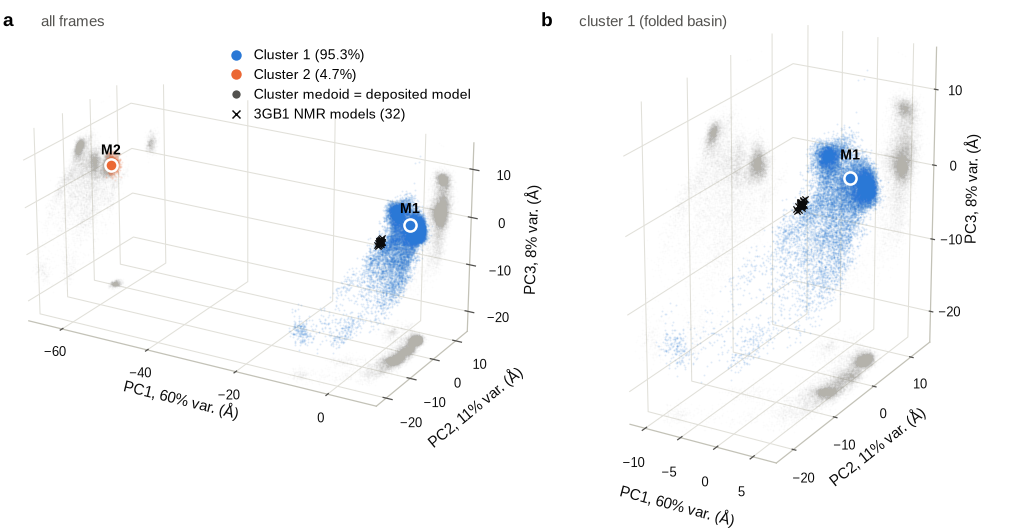

In [8]:
def landscape_3d(ax, P, labels, medoids, ref, variance, sel, elev=22, azim=-60):
    # frames on PC1-3 (equal Å scale) coloured by cluster, wall shadows, reference, medoids
    ax.computed_zorder = False               # draw in call order: clouds, reference, medoids
    Q = P[sel]
    lo, hi = Q.min(axis=0), Q.max(axis=0)
    lo, hi = lo - 0.04 * (hi - lo), hi + 0.04 * (hi - lo)
    ax.set(xlim=(lo[0], hi[0]), ylim=(lo[1], hi[1]), zlim=(lo[2], hi[2]))
    ax.set_box_aspect(hi - lo)               # the same length per Å on all three axes
    shadow = {"s": 0.5, "color": SHADOW, "alpha": 0.035, "lw": 0, "rasterized": True,
              "depthshade": False}
    ax.scatter(Q[:, 0], Q[:, 1], np.full(len(Q), lo[2]), **shadow)
    ax.scatter(Q[:, 0], np.full(len(Q), hi[1]), Q[:, 2], **shadow)
    ax.scatter(np.full(len(Q), lo[0]), Q[:, 1], Q[:, 2], **shadow)
    for c in [-1, *range(len(medoids))[::-1]]:          # noise first, cluster 1 on top
        m = sel & (labels == c)
        if m.any():
            ax.scatter(*P[m].T, s=0.8, color=NOISE if c < 0 else CLUSTER[c % 3], alpha=0.15,
                       lw=0, rasterized=True, depthshade=False)
    inside = np.all((ref >= lo) & (ref <= hi), axis=1)
    ax.scatter(*ref[inside].T, s=9, marker="x", color=INK, lw=0.6, depthshade=False)
    for c, f in enumerate(medoids):
        if sel[f]:
            ax.scatter(*P[f], s=34, color=CLUSTER[c % 3], edgecolors="white", linewidths=1.2,
                       depthshade=False)
            ax.text(*(P[f] + [0, 0, 0.06 * (hi[2] - lo[2])]), f"M{c + 1}", fontsize=6.5,
                    fontweight="bold", ha="center")
    for i, axis in enumerate((ax.xaxis, ax.yaxis, ax.zaxis)):
        axis.set_major_locator(MaxNLocator(nbins=4, steps=[1, 2, 5, 10]))
        axis.set_pane_color((1, 1, 1, 0))
        axis.line.set_color(AXIS)
        axis.line.set_linewidth(0.6)
        axis.set_label_text(f"PC{i + 1}, {100 * variance[i]:.0f}% var. (Å)")
    ax.xaxis.labelpad = ax.yaxis.labelpad = -4
    ax.zaxis.labelpad = -5
    ax.tick_params(labelsize=6, pad=0)
    ax.patch.set_alpha(0)                    # keeps the neighbouring panel's labels visible
    ax.view_init(elev=elev, azim=azim)


nmr_proj = np.array([project(superpose(x[None], g.origin)[0], g)[0] for x in nmr_ca])
P = traj.projections
fig = plt.figure(figsize=(DOUBLE, 3.3))
axes = [fig.add_subplot(1, 2, i, projection="3d") for i in (1, 2)]
landscape_3d(axes[0], P, labels, clusters.representatives, nmr_proj, g.variance_fraction,
             sel=np.ones(n, bool))
landscape_3d(axes[1], P, labels, clusters.representatives, nmr_proj, g.variance_fraction,
             sel=labels == 0)
for ax, letter, what in zip(axes, "ab", ["all frames", "cluster 1 (folded basin)"],
                            strict=True):
    ax.text2D(0.0, 0.95, letter, transform=ax.transAxes, fontsize=9, fontweight="bold")
    ax.text2D(0.08, 0.95, what, transform=ax.transAxes, color=INK_2)
handles = [Line2D([], [], ls="", marker="o", ms=4, color=CLUSTER[c % 3],
                  label=f"Cluster {c + 1} ({100 * np.mean(labels == c):.1f}%)")
           for c in range(clusters.n_clusters)]
if clusters.noise_fraction > 0:
    handles.append(Line2D([], [], ls="", marker="o", ms=4, color=NOISE, label="Noise"))
handles += [Line2D([], [], ls="", marker="o", ms=5, color=INK_2, mec="white", mew=1,
                   label="Cluster medoid = deposited model"),
            Line2D([], [], ls="", marker="x", ms=4, color=INK, mew=0.7,
                   label=f"{native.label.split()[-1]} NMR models ({len(nmr_proj)})")]
fig.legend(handles=handles, loc="upper left", bbox_to_anchor=(0.2, 0.93), handletextpad=0.3,
           labelspacing=0.5)
fig.subplots_adjust(left=0.0, right=0.97, bottom=0.04, top=1.0, wspace=0.12)
save(fig, "fig2_pc_landscape_3d")
plt.show()

## 4. Calculating State Modes and Generating the mmCIF File

Within each cluster, we compute the local positional covariance matrix and diagonalize it. 

This yields the top three collective modes per basin. Scaling each unit eigenvector by the square root of its eigenvalue gives the realistic physical displacement in angstroms. Finally, we write the coordinates, modes, and metadata directly to disk using `mdcif`.

The file also gets the PCA of the whole run (Section 2), the frames' PC1–3 coordinates, the
populations and precisions (Section 3), and the simulation conditions from
[`provenance.yaml`](provenance.yaml). Here the per-state analysis uses the Cα atoms without
mass weighting (the `modes:` block of the YAML), which is the same as a PCA of each state's
frames.

**Why no mass weighting?** Textbook quasi-harmonic analysis weights each atom by its mass. Here
every analysed atom is a Cα and they all weigh the same, so weighting would only change the units
of the eigenvalues (amu·Å² instead of Å²), not the motions. The masses in this topology are also
not the real ones: its hydrogens were made heavier, at the expense of the atoms they are bonded
to, to allow the 4 fs time step. So when mass weighting is switched on (`mass_weighted: true`),
mdcif uses the standard element masses, and the viewers use the same masses to turn each
eigenvalue back into a size in Å.

**Starting from the PDB entry.** With `reference="3GB1"` the file is an edited copy of 3GB1: the protein's name, sequence, chain, residue numbering, organism, UniProt link and citations come from the entry, and its 32 NMR models are replaced by the medoids, superposed on NMR model 1.

------------------

<div class="alert alert-block alert-info">
<b>Validation:</b> <code>validate_mdcif</code> checks the file against the official PDBx/mmCIF and IHM
dictionaries and against mdcif's own dictionary for the six new categories
(<a href="../../docs/spec/mdcif_ext.dic"><code>mdcif_ext.dic</code></a>), then runs a few sanity checks
(unit-length vectors, eigenvalues largest first, projections that point at real models).
</div>

In [ ]:
from mdcif.provenance import load_provenance
from mdcif.validate import validate_mdcif

prov = load_provenance("provenance.yaml")
summary = save_mdcif(OUT, traj, clusters, prov, reference="3GB1")
# save_mdcif(OUT.with_suffix(".bcif"), traj, clusters, prov, reference="3GB1")  # BinaryCIF
print(summary.report())
validate_mdcif(OUT)   # raises with the list of problems if anything is wrong
print("\nvalid: PDBx + IHM + mdcif_ext dictionaries, mode checks")
for path in (TRAJ, OUT, OUT.with_suffix(".bcif")):
    print(f"{path.name:22s} {path.stat().st_size / 1024 ** 2:9.2f} MB")

gb1_meld_300K.cif: 17683 frames, 56 analysis atoms, 435 deposited atoms
  global PCA var% 60/11/8 (cum 79%)
  clustering: HDBSCAN on PCA projection (global PCs 1-3), min_cluster_size 177, 2 clusters
  model 1: 16847 frames (95.3%), medoid frame 142700, t = 285.402 ns, precision 1.61 A, RMSD to PDB 3GB1 model 1 2.61 A, modes var% 26/20/8 (cum 54%)
  model 2:   836 frames ( 4.7%), medoid frame 127120, t = 254.242 ns, precision 0.93 A, RMSD to PDB 3GB1 model 1 9.04 A, modes var% 20/14/9 (cum 43%)
  timings: modes 0.6s, reference 0.1s, write 0.1s



valid: PDBx + IHM + mdcif_ext dictionaries, mode checks
meld.nc.001              1972.49 MB
gb1_meld_300K.cif           0.27 MB
gb1_meld_300K.bcif          0.14 MB


The 2 GB trajectory is now a 0.3 MB text file (0.15 MB as BinaryCIF). The report already shows the result per state: the best populated state (model 1) is 2.6 Å from the NMR structure and the other state (model 2) 9 Å, and each has its own top three modes saved ("modes var%": each mode's share of that state's motion).

## 5. A tour of the file

From here on, everything is read back from the file. `show` prints one category as a table;
`read_mdcif` returns the same data as numpy arrays.

In [10]:
from mdcif.reader import read_mdcif

block = gemmi.cif.read(str(OUT)).sole_block()
data = read_mdcif(OUT)


def rows(category):
    # one dict per row of an mmCIF category, values as strings ('?' / '.' -> None)
    table = block.find_mmcif_category(f"_{category}.")
    tags = [t.split(".", 1)[1] for t in table.tags]
    return [{t: (None if gemmi.cif.is_null(v) else gemmi.cif.as_string(v))
             for t, v in zip(tags, row)} for row in table]


def show(category, n_rows=None, cap=16):
    # print a category as a table, one column per item (long values shortened to cap)
    rs = rows(category)
    print(f"_{category}: {len(rs)} rows")
    cols = list(rs[0])
    shown = rs[:n_rows]
    width = {c: min(cap, max(len(c), *(len(str(r[c])) for r in shown))) for c in cols}
    print("  ".join(f"{c[:width[c]]:>{width[c]}s}" for c in cols))
    for r in shown:
        print("  ".join(f"{str(r[c])[:width[c]]:>{width[c]}s}" for c in cols))
    if len(shown) < len(rs):
        print("...")

### 5.1 `_mdcif_simulation`: how the simulation was run

| Item | Meaning |
|---|---|
| `id`, `protocol_id`, `software_id` | links to the modelling protocol and the MD engine (`software`) |
| `force_field`, `water_model` | the physics |
| `ensemble`, `temperature`, `pressure` | thermodynamic conditions (K, bar) |
| `timestep`, `length`, `num_replicas`, `frame_interval` | fs, ns per replica, number of replicas, ps between saved frames |
| `enhanced_sampling`, `details` | the sampling method (here MELD replica exchange) and free text |

Standard IHM can record *that* a simulation was run, but has no place for these conditions, and
without them the states and motions below cannot be interpreted.

In [11]:
sim = rows("mdcif_simulation")[0]
for key, value in sim.items():
    text = "" if value is None else str(value)
    print(f"{key:18s} {text[:90]}{'...' if len(text) > 90 else ''}")
T = float(sim["temperature"])

id                 1
protocol_id        1
software_id        1
force_field        ff19SB
water_model        implicit: GB-Neck2 (igb=8, mbondi3 radii)
ensemble           NVT
temperature        300
pressure           
timestep           4
length             403.650
num_replicas       30
frame_interval     2
enhanced_sampling  MELD: temperature + Hamiltonian replica exchange
details            MELD (Modeling Employing Limited Data) folding from an extended chain built from sequence ...


### 5.2 `_mdcif_mode_set`: one row per analysis

| Item | Meaning |
|---|---|
| `model_id`, `ensemble_id` | the model whose atoms the vectors belong to (model 1 for the global set), and the state (empty for the global set) |
| `method` | `PCA`, or `quasi-harmonic` if the atoms were weighted by their mass |
| `atom_selection`, `num_frames` | which atoms and how many frames went in |
| `total_variance` | the total motion over *all* modes, Å², so the share kept by the three stored modes is known |

Set 1 is the PCA of the whole run; sets 2 and 3 belong to the folded and the misfolded state
(models 1 and 2).

In [12]:
show("mdcif_mode_set")

_mdcif_mode_set: 3 rows
id  model_id  ensemble_id  method  atom_selection  num_frames  total_variance
 1         1         None     PCA         name CA       17683         335.956
 2         1            1     PCA         name CA       16847         141.621
 3         2            2     PCA         name CA         836         38.6431


### 5.3 `_mdcif_mode`: the eigenvalues

| Item | Meaning |
|---|---|
| `mode_set_id` | the analysis; within it, mode 1 is the one with the largest eigenvalue |
| `eigenvalue` | the size of the motion along the mode, Å² (its square root is in Å) |

A mode's share of its state's motion is its eigenvalue divided by `total_variance`
(Section 5.2), so the file does not store it separately. These few numbers are already enough
to compare the two states.

In [13]:
show("mdcif_mode")
sets = {int(r["id"]): r for r in rows("mdcif_mode_set")}
eig = {}
for r in rows("mdcif_mode"):
    eig.setdefault(int(r["mode_set_id"]), []).append(float(r["eigenvalue"]))
eig = {sid: np.array(ev) for sid, ev in eig.items()}

print()
for sid, s in sets.items():
    who = "whole run" if s["ensemble_id"] is None else f"model {s['model_id']}"
    print(f"set {sid} ({who}): size of modes 1-3 = "
          + ", ".join(f"{np.sqrt(x):4.1f}" for x in eig[sid])
          + f" Å; together {100 * eig[sid].sum() / float(s['total_variance']):.0f}% of its motion")

state = {int(s["model_id"]): eig[sid] for sid, s in sets.items() if s["ensemble_id"] is not None}
if len(state) >= 2:
    dS = 0.5 * np.sum(np.log(state[2] / state[1]))   # quasi-harmonic entropy change, in k_B
    print(f"\nentropy change from model 1 to model 2, 3 stored modes: {dS:.1f} k_B "
          f"(T·ΔS = {dS * 0.0019872 * T:.1f} kcal/mol at T = {T:g} K from _mdcif_simulation)")

_mdcif_mode: 9 rows
id  mode_set_id  eigenvalue
 1            1     203.127
 2            1     35.4994
 3            1     25.6249
 4            2     37.4335
 5            2     28.5361
 6            2     10.7676
 7            3      7.5921
 8            3      5.5748
 9            3     3.34847

set 1 (whole run): size of modes 1-3 = 14.3,  6.0,  5.1 Å; together 79% of its motion
set 2 (model 1): size of modes 1-3 =  6.1,  5.3,  3.3 Å; together 54% of its motion
set 3 (model 2): size of modes 1-3 =  2.8,  2.4,  1.8 Å; together 43% of its motion

entropy change from model 1 to model 2, 3 stored modes: -2.2 k_B (T·ΔS = -1.3 kcal/mol at T = 300 K from _mdcif_simulation)


The folded state (model 1) moves about twice as much as the misfolded state along each of its
three modes (6.1 vs 2.8 Å for mode 1). In the quasi-harmonic picture, larger fluctuations mean
more entropy, and the entropy difference between two states follows from the ratio of their
eigenvalues. Within the three stored modes, the misfolded state has about 2 $k_B$ (1.3 kcal/mol
at 300 K) less: a rough measure of how much stiffer it is, not a full entropy.

### 5.4 `_mdcif_mode_vector`: the eigenvectors

| Item | Meaning |
|---|---|
| `mode_id` | the mode (row of `_mdcif_mode`) |
| `atom_id` | the atom (`_atom_site.id`) in the set's model |
| `dx`, `dy`, `dz` | the direction in which this atom moves along the mode |

One row per mode and atom: 3 modes × 56 Cα atoms per set. Taken over all atoms, each eigenvector
has length 1; multiplied by √eigenvalue it becomes the actual displacement in Å. The vectors
are in the same frame as the models (here the 3GB1 frame), so they can be added straight onto
the stored coordinates.

In [14]:
show("mdcif_mode_vector", n_rows=4)
print()
for who, ms in [("whole run", data.global_modes)] + [(f"model {m}", s) for m, s in
                                                     sorted(data.mode_sets.items())]:
    length = np.linalg.norm(ms.eigenvectors.reshape(ms.n_modes, -1), axis=1)
    print(f"{who:9s}: length of eigenvectors 1-3 = " + ", ".join(f"{x:.4f}" for x in length))

_mdcif_mode_vector: 504 rows
mode_id  atom_id         dx          dy         dz
      1        2  -0.416431  -0.0560981   0.161491
      1       10  -0.324888  -0.0199873   0.136548
      1       17  -0.241222  -0.0483858  0.0714437
      1       29  -0.148331  -0.0210849   0.060331
...

whole run: length of eigenvectors 1-3 = 1.0000, 1.0000, 1.0000
model 1  : length of eigenvectors 1-3 = 1.0000, 1.0000, 1.0000
model 2  : length of eigenvectors 1-3 = 1.0000, 1.0000, 1.0000


**Which residues move?** Multiplying an atom's $(dx, dy, dz)$ by √eigenvalue gives how far that
Cα moves along the mode (one standard deviation). Figure 3 plots this per residue for both
states, over the secondary structure of 3GB1 (taken from the entry).

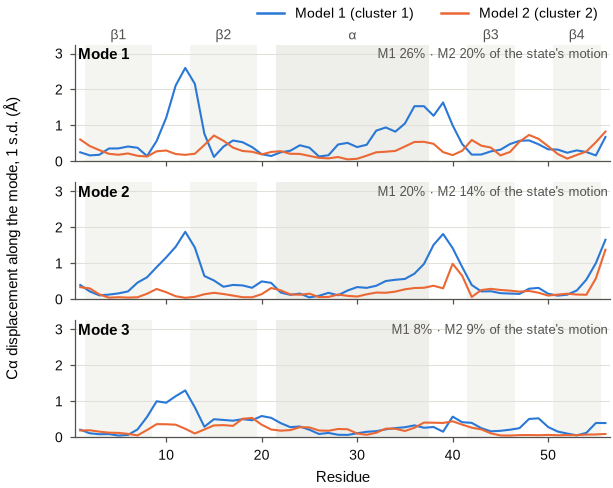

In [15]:
ss = [("α", h.start.res_id.seqid.num, h.end.res_id.seqid.num) for h in nmr.helices]
strands = sorted((strand.start.res_id.seqid.num, strand.end.res_id.seqid.num)
                 for sheet in nmr.sheets for strand in sheet.strands)
ss += [(f"β{i + 1}", a, b) for i, (a, b) in enumerate(strands)]
model_atoms = {int(m._id): list(m.get_atoms()) for _, m in data.system._all_models()}

n_modes = 3
fig, axes = plt.subplots(n_modes, 1, figsize=(4.6, 3.4), sharex=True, sharey=True,
                         gridspec_kw={"hspace": 0.18})
top = 0
for k, ax in enumerate(axes):
    for name, a, b in ss:
        ax.axvspan(a - 0.5, b + 0.5, color=GRID, alpha=0.55 if name == "α" else 0.35, lw=0)
    shares = []
    for c, (mid, atoms) in enumerate(sorted(model_atoms.items())):
        ms = data.mode_sets[mid]
        res = np.array([atoms[i].seq_id for i in ms.atom_indices])
        amp_k = np.sqrt(ms.eigenvalues[k]) * np.linalg.norm(ms.eigenvectors[k], axis=1)
        top = max(top, amp_k.max())
        ax.plot(res, amp_k, color=CLUSTER[c % 3], lw=1.0)
        shares.append(f"M{mid} {100 * ms.variance_fraction[k]:.0f}%")
    ax.text(0.005, 0.97, f"Mode {k + 1}", transform=ax.transAxes, fontweight="bold", va="top")
    ax.text(0.995, 0.97, " · ".join(shares) + " of the state's motion",
            transform=ax.transAxes, va="top", ha="right", fontsize=6, color=INK_2)
    ax.yaxis.grid(True)
    ax.set_axisbelow(True)
axes[0].set_ylim(0, 1.25 * top)
for name, a, b in ss:
    axes[0].text((a + b) / 2, 1.02, name, transform=axes[0].get_xaxis_transform(),
                 ha="center", va="bottom", fontsize=6.5, color=INK_2)
n_res = max(a.seq_id for a in model_atoms[1])
axes[-1].set(xlim=(0.5, n_res + 0.5), xlabel="Residue")
fig.supylabel("Cα displacement along the mode, 1 s.d. (Å)", fontsize=7, x=0.02)
axes[0].legend(handles=[Line2D([], [], color=CLUSTER[c % 3], lw=1.2,
                               label=f"Model {mid} (cluster {mid})")
                        for c, mid in enumerate(sorted(model_atoms))],
               loc="lower right", bbox_to_anchor=(1.0, 1.1), ncol=2)
save(fig, "fig3_mode_profiles")
plt.show()

**Figure 3.** How far each residue moves along the first three modes of each state, read from
`_mdcif_mode` and `_mdcif_mode_vector`. Shading: secondary structure of 3GB1 (β-strands light,
α-helix darker). Top right of each panel: the mode's share of its state's motion.

In the folded state (model 1) the motion is in the loops: the β1–β2 hairpin (residues 9–13)
dominates mode 1, together with the end of the helix and the α–β3 loop (residues 36–41). The
strands and most of the helix stay put. The misfolded state (model 2) moves less everywhere.

### 5.5 `_mdcif_mode_origin`: the average structure

| Item | Meaning |
|---|---|
| `mode_set_id` | the global set (1) |
| `atom_id` | the atom (`_atom_site.id`) in model 1 |
| `x`, `y`, `z` | its average position over the whole run, Å |

The average structure makes the PC1–3 map reusable. To place *any* structure of the same protein
on the map, superpose it on the average, subtract the average, and multiply by each PC's
eigenvector. That is how the 32 NMR models were placed in Fig. 2. Below, the same is done using
only the file and compared with the in-memory result; then the two models are placed on the map
from their stored coordinates.

In [16]:
from mdcif.plot import model_projections, reference_projections

show("mdcif_mode_origin", n_rows=3)
_, nmr_from_file = reference_projections(data, "3GB1")
print(f"\nNMR models placed from the file vs in memory: largest difference "
      f"{np.abs(nmr_from_file - nmr_proj).max():.4f} Å")
medoid_p = model_projections(data)
fmt = lambda p: "(" + ", ".join(f"{x:7.2f}" for x in p) + ")"
for c, f in enumerate(clusters.representatives):
    print(f"model {c + 1}: placed from the file at PC1-3 = {fmt(medoid_p[c + 1])} Å; "
          f"its frame in memory {fmt(P[f])} Å")

_mdcif_mode_origin: 56 rows
mode_set_id  atom_id        x       y      z
          1        2  -13.463  -4.527  4.296
          1       10  -10.739  -3.579  4.437
          1       17   -7.780  -3.906  2.752
...

NMR models placed from the file vs in memory: largest difference 0.0003 Å
model 1: placed from the file at PC1-3 = (   4.10,    0.83,    2.26) Å; its frame in memory (   4.10,    0.83,    2.26) Å
model 2: placed from the file at PC1-3 = ( -63.18,   -0.07,    2.02) Å; its frame in memory ( -63.18,   -0.06,    2.07) Å


Both agree to a few hundredths of an Å. (A single structure is superposed on the average, while
the frames were superposed in a slightly different way during the analysis, hence the small
differences.)

### 5.6 `_mdcif_projection`: the map

| Item | Meaning |
|---|---|
| `frame`, `time` | frame number in the trajectory, time in ps |
| `model_id` | the frame's state, i.e. its model (`.` = noise) |
| `proj_1`, `proj_2`, `proj_3` | the frame's coordinates on PC1–3, Å |

Up to 5,000 evenly spaced frames are stored, always on the global PCs (set 1). These rows alone redraw Fig. 2 (`mdcif landscape`
does just that), give the state populations, and even rebuild approximate structures: the
average structure plus each PC coordinate times its eigenvector. Below, the rebuilt frames are
compared with the real ones, which only the trajectory has.

In [17]:
show("mdcif_projection", n_rows=4)
stored = data.projection
idx = np.searchsorted(traj.frames, stored["frame"])      # stored frames -> analysed frames
same = np.array_equal(stored["model_id"], np.where(labels[idx] >= 0, labels[idx] + 1, 0))
print(f"\nstored vs in-memory PC coordinates: largest difference "
      f"{np.abs(stored['coords'] - P[idx]).max():.4f} Å; same state for every frame: {same}")
pops = np.bincount(stored["model_id"]) / len(idx)
print("populations from the stored frames:", ", ".join(f"model {m}: {100 * p:.1f}%"
                                                       for m, p in enumerate(pops) if m))

G = data.global_modes                                    # average structure + PC vectors
rebuilt = G.origin + np.einsum("tk,kia->tia", stored["coords"], G.eigenvectors)
fit = np.array([fitted_rmsd(a, b, center=True, superposition=True)
                for a, b in zip(rebuilt, traj.aligned[idx], strict=True)])
print(f"{len(idx)} frames rebuilt from 3 numbers each: Cα RMSD to the real frame "
      f"{np.median(fit):.2f} Å (median)")

_mdcif_projection: 5000 rows
frame       time  model_id  proj_1  proj_2  proj_3
25000  50002.000         1   7.073  -3.288   2.653
25040  50082.000         1   3.584  -1.548   0.587
25070  50142.000         1   4.240  -8.569  -1.811
25110  50222.000         1   3.003  -5.830   1.452
...

stored vs in-memory PC coordinates: largest difference 0.0005 Å; same state for every frame: True
populations from the stored frames: model 1: 95.3%, model 2: 4.7%


5000 frames rebuilt from 3 numbers each: Cα RMSD to the real frame 0.96 Å (median)


Three numbers per frame give back the Cα trace to about 1 Å. The rest of the picture is in
existing PDBx/IHM categories:

| Existing category | Holds |
|---|---|
| `atom_site`, `ihm_model_list` | the medoid coordinates, one model per state (model 1 = most populated) |
| `ihm_model_group`, `ihm_ensemble_info`, `ihm_model_representative` | each state's population and precision, with its medoid as representative |
| `ihm_modeling_protocol`, `ihm_modeling_post_process`, `software` | the MD run as a modelling step; clustering and the comparison with 3GB1 as post-processing |
| `entity`, `struct_asym`, `struct_ref`, `citation` | the molecule and its literature, reused from 3GB1 |

## 6. Looking at it in 3D

The PyMOL and ChimeraX plugins read the file with their own small reader, `mdcif_data.py`
(plain Python and numpy, no mdcif install needed). Here it feeds py3Dmol. The two models,
already superposed on 3GB1 (grey):

In [18]:
sys.path.insert(0, str(Path("../../../viewers/pymol").resolve()))
from mdcif_pymol.mdcif_data import MdcifFile, mode_frames

f = MdcifFile(OUT)
st = gemmi.read_structure(str(OUT))
models = {m: cif_atoms(st[i]) for i, m in enumerate(f.models)}

view = py3Dmol.view(width=640, height=400)
view.addModel(pdb_text(native_atoms, native_xyz), "pdb")
view.setStyle({"model": 0}, {"cartoon": {"color": "#b4b2ab", "opacity": 0.7}})
for i, (atoms, xyz) in enumerate(models.values(), 1):
    view.addModel(pdb_text(atoms, xyz), "pdb")
    view.setStyle({"model": i}, {"cartoon": {"color": CLUSTER[(i - 1) % 3]}})
view.zoomTo()
view.show()

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

**A mode as a movie.** Model 1 swinging back and forth along its mode 1, up to 3 standard
deviations each way (3 × √eigenvalue along the eigenvector). Side chains follow their residue's
Cα; only the backbone is drawn.

In [19]:
model, mode = 1, 1
atoms, xyz = models[model]
keys = [(a[2], str(a[3]), a[0]) for a in atoms]
ms = f.mode_set(model)
movie_xyz = mode_frames(xyz, keys, ms, mode, amplitude=3.0, n_frames=16)
backbone = np.array([a[0] in ("N", "CA", "C", "O") for a in atoms])
bb_atoms = [a for a, keep in zip(atoms, backbone, strict=True) if keep]
movie = "".join(pdb_text(bb_atoms, fr[backbone], model=k + 1) for k, fr in enumerate(movie_xyz))

view = py3Dmol.view(width=640, height=400)
view.addModelsAsFrames(movie, "pdb")
view.setStyle({"cartoon": {"color": CLUSTER[0]}})
view.animate({"loop": "forward", "interval": 90})
view.zoomTo()
view.show()
print(f"model {model}, mode {mode}: {100 * ms.variance_fraction[mode - 1]:.0f}% of its state's "
      f"motion, √eigenvalue = {np.sqrt(ms.eigenvalues[mode - 1]):.1f} Å")

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

model 1, mode 1: 26% of its state's motion, √eigenvalue = 6.1 Å


**The same mode as a picture.** One arrow per Cα, showing which way and how far it moves along
the mode (3 standard deviations; arrows under 0.5 Å hidden). Drawn by the PyMOL plugin from the
file and ray-traced.

 gb1_m1_mode1_porcupine: 51 arrows, cluster mode 1 of model 1, 3 sd


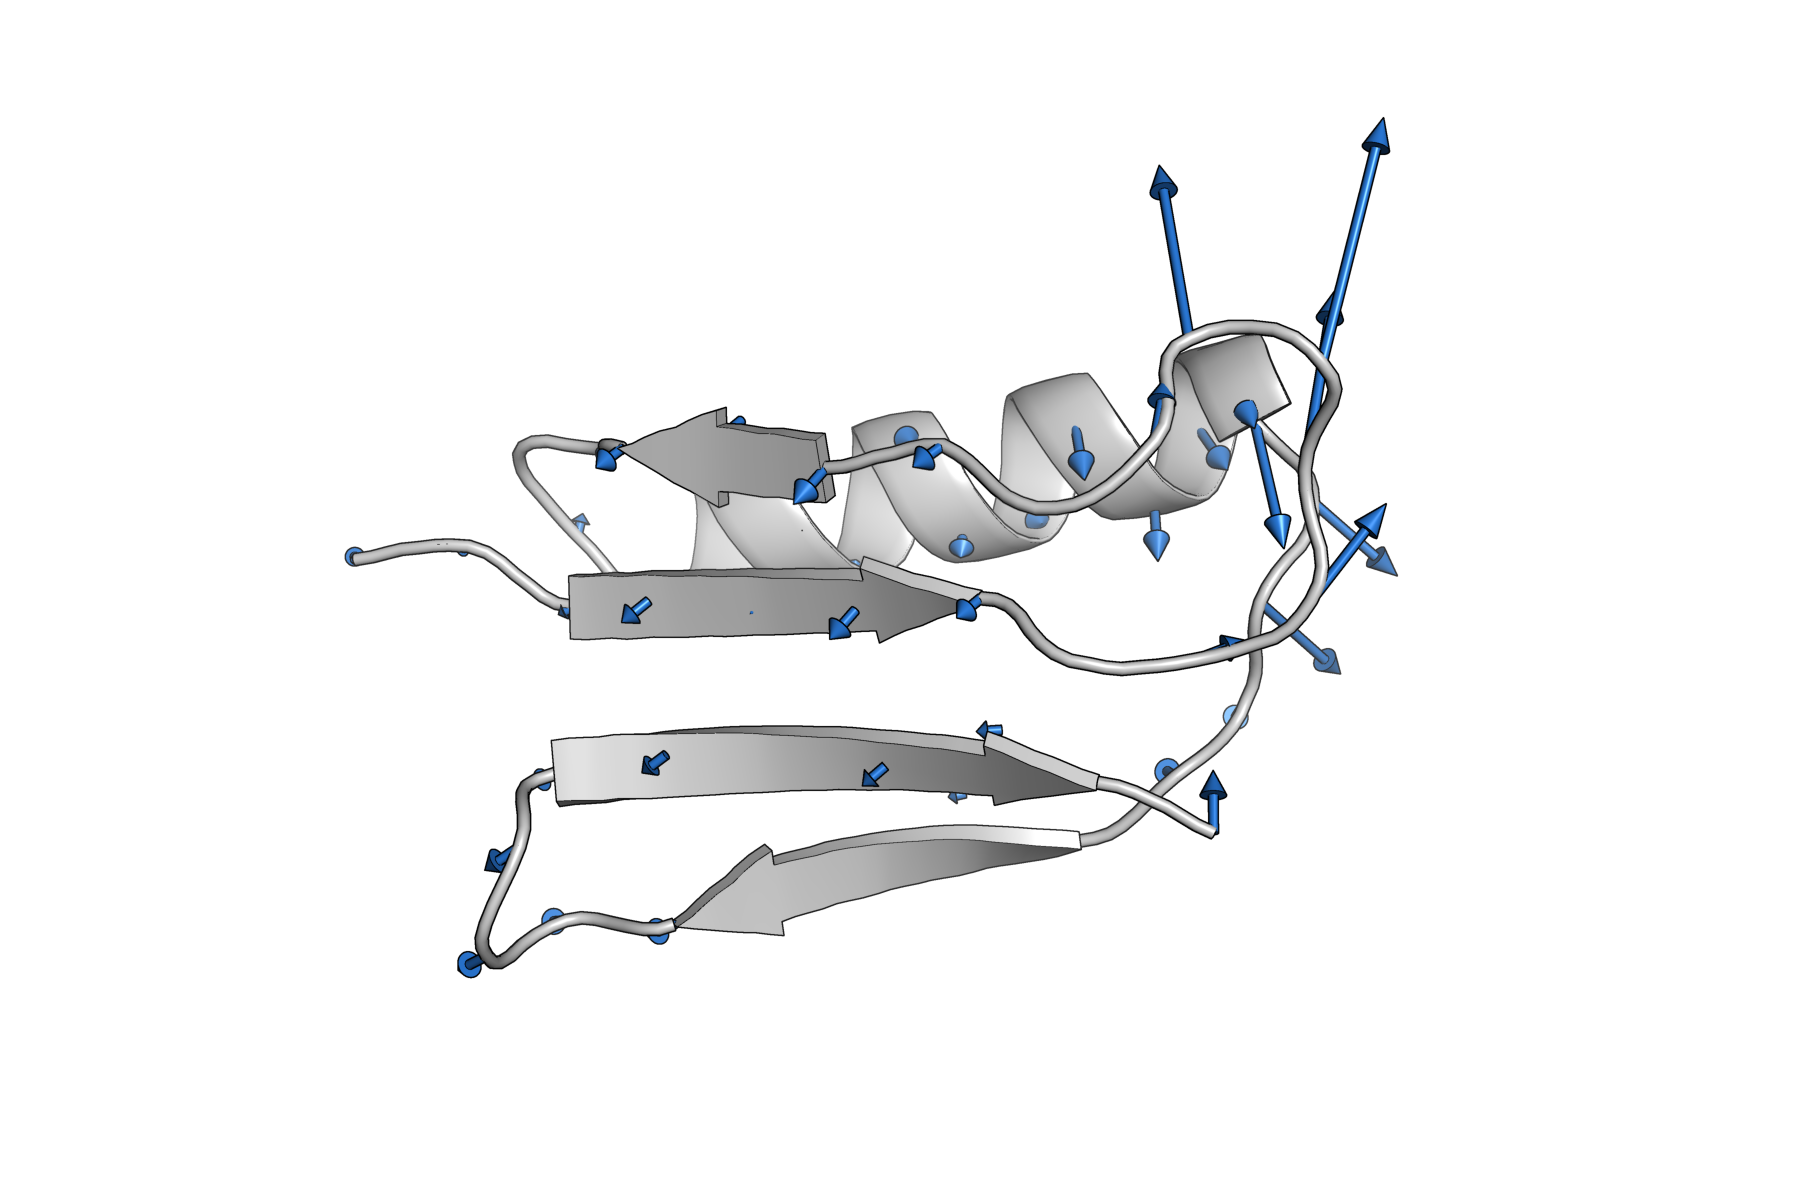

In [20]:
import mdcif_pymol
from pymol import cmd

cmd.reinitialize()
mdcif_pymol.mdcif_load(str(OUT), "gb1", quiet=1)
cmd.hide("everything", "gb1")
cmd.show("cartoon", "gb1")
cmd.color("grey80", "gb1")
mdcif_pymol.mdcif_porcupine("gb1", model=1, mode=1, scale=3.0, color="0x2a78d6")
cmd.bg_color("white")
cmd.set("ray_opaque_background", 1)
cmd.set("antialias", 2)
cmd.set("ray_trace_mode", 1)          # thin black outlines, print style
cmd.set("ray_shadows", 0)
cmd.orient("gb1")
png = FIGS / "fig4_porcupine_pymol.png"
cmd.png(str(png), width=1800, height=1200, dpi=600, ray=1)
display(Image(str(png), width=600))

**Figure 4.** Mode 1 of model 1 (folded state) as a porcupine plot, drawn by the mdcif PyMOL
plugin from the file alone. Arrows: Cα displacement at 3 standard deviations. A mode describes
motion in both directions, so the arrows could equally point the other way.

The same in PyMOL or ChimeraX:

| | PyMOL | ChimeraX |
|---|---|---|
| open | `mdcif_load gb1_meld_300K.cif, gb1` | `mdcif open gb1_meld_300K.cif` |
| list modes | `mdcif_modes gb1` | `mdcif modes #1` |
| morph between models | `mdcif_morph gb1` | `mdcif morph #1` |
| animate a mode | `mdcif_animate gb1, model=1, mode=1` | `mdcif animate #1.1 mode 1` |
| a global PC instead | `mdcif_animate gb1, model=2, mode=1, scope=global` | `mdcif animate #1.2 mode 1 scope global` |
| porcupine | `mdcif_porcupine gb1, model=1, mode=1` | `mdcif porcupine #1.1 mode 1` |

The whole notebook in one terminal command: `mdcif build ../../data/3gb1/meld/3gb1_HMR.prmtop
../../data/3gb1/meld/meld.nc.001 --provenance provenance.yaml --start 25000 --step 10 --output
gb1.cif` ([3_cli](../3_cli/3_cli.ipynb) shows the command line step by step).